# Transit Detection using Box Least Squares (BLS) & Multi-Planet Masking
### Stage 1: Exoplanet Periodic Transit Signal Detection & Vetting
**AIML PBL Project: Exoplanet Detection from TESS Light Curves**

This notebook walks through the transit detection and vetting methodology implemented in `src/detect.py`.
When an exoplanet orbits a star, it periodically transits between the star and the telescope, causing a shallow, box-like dip in the measured normalized flux.

#### Detection Workflow:
1. **Cadence & Binning**: Resample high-cadence (2-min) light curves into 10-minute bins to drastically accelerate the search without distorting transit signals.
2. **Log-Spaced Period Grid**: Generate a grid where phase drift over the observational baseline $\Delta t$ is bounded: $d(\ln P) \le \tau_{\min} / (3 \times \Delta t)$.
3. **Box Least Squares (BLS)**: Search across trial periods and durations to find periodic box-shaped dips.
4. **Parameter Refinement**: Refine the candidate period, transit center $T_0$, and duration $\tau$ on the full-cadence data with a high-resolution grid.
5. **Statistical Vetting**:
   - **Odd vs. Even Transit Depth**: Identify eclipsing binaries with alternating depths ($\Delta \sigma_{\text{odd-even}} < 3\sigma$).
   - **Secondary Eclipse**: Check for occultation at phase 0.5 ($\sigma_{\text{sec}} < 3\sigma$).
   - **Red-Noise SNR**: Calculate scatter on the transit duration timescale to account for correlated stellar noise.
   - **Transit Count & Duty Cycle**: Require $\ge 2$ covered transits and reasonable duration fraction ($\tau / P < 0.1$).
6. **Iterative Planet Masking**: Mask the transits of the accepted signal and repeat BLS to discover additional planets in multi-planet systems!

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root reliably (handles running from repo root or notebooks/)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "detect.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "detect.py").exists():
    ROOT = Path(r"d:\koyal college work\SEM5\AIML\AIML PBL\exoplanet-detection")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from astropy.timeseries import BoxLeastSquares
import detect
from detect import (
    load_input,
    cadence_minutes,
    bin_series,
    make_period_grid,
    bls_search,
    refine,
    red_noise_snr,
    vet,
    calibrate_errors,
    phase_offset,
    plot_periodogram,
    plot_fold,
    plot_overview,
)

# Standard result columns for summary tables across all detection steps
SHOW_COLS = [
    "planet", "period_d", "duration_h", "depth_ppm", "snr", "snr_red", "sde",
    "n_transits", "odd_even_sigma", "secondary_sigma", "flags", "status"
]

# Matplotlib styling for high-contrast, clean figures
plt.rcParams.update({
    "figure.autolayout": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

# Robust helper functions to allow running cells out of order
def ensure_light_curve_loaded():
    """Ensures time, flux, flux_err, star_name, and baseline_d are initialized."""
    global time, flux, flux_err, star_name, baseline_d, cadence_min
    if "time" not in globals() or "flux" not in globals() or time is None:
        csv_path = ROOT / "data" / "full" / "processed_TIC_307210830.csv"
        if not csv_path.exists():
            raise FileNotFoundError(f"Light curve CSV not found at {csv_path}. Please check data/full/")
        time, flux, flux_err, star_name = load_input(csv=str(csv_path))
        if flux_err is not None:
            flux_err = calibrate_errors(flux, flux_err, verbose=False)
        baseline_d = float(time.max() - time.min())
        cadence_min = cadence_minutes(time)
        print(f"Auto-loaded benchmark data: {star_name} ({len(time):,} points, {baseline_d:.1f} days baseline)")

def ensure_period_grid():
    """Ensures binned light curve (tb, fb, eb) and period search grid are initialized."""
    global tb, fb, eb, durations_h, durations_d, period_min, period_max, periods
    ensure_light_curve_loaded()
    if "tb" not in globals() or tb is None or len(tb) == 0:
        tb, fb, eb = bin_series(time, flux, flux_err if flux_err is not None else np.ones_like(flux), minutes=10)
    if "periods" not in globals() or "durations_d" not in globals() or periods is None:
        durations_h = (0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0)
        durations_d = np.array(durations_h) / 24.0
        period_min = 0.5
        period_max = min(baseline_d / 2.0, 40.0)
        periods = make_period_grid(baseline_d, period_min, period_max, durations_d.min())

print(f"Project root: {ROOT}")
print("Successfully loaded libraries, src/detect modules, and out-of-order execution helpers.")

Project root: D:\koyal college work\SEM5\AIML\AIML PBL\exoplanet-detection
Successfully loaded libraries, src/detect modules, and out-of-order execution helpers.


## Step 1: Loading Preprocessed Light Curve Data
We load the preprocessed full-cadence light curve for benchmark system **TIC 307210830** (L 98-59 / TOI-175).
This star is a bright M-dwarf host to three confirmed terrestrial planets with periods of ~2.25 d, ~3.69 d, and ~7.45 d.

In [2]:
csv_path = ROOT / "data" / "full" / "processed_TIC_307210830.csv"
if not csv_path.exists():
    raise FileNotFoundError(f"Light curve CSV not found at {csv_path}. Please check data/full/")

time, flux, flux_err, star_name = load_input(csv=str(csv_path))
if flux_err is not None:
    flux_err = calibrate_errors(flux, flux_err, verbose=True)

baseline_d = float(time.max() - time.min())
cadence_min = cadence_minutes(time)

print(f"Target: {star_name}")
print(f"Data points: {len(time):,}")
print(f"Observational baseline: {baseline_d:.2f} days (~{baseline_d / 27:.1f} TESS sectors)")
print(f"Cadence: {cadence_min:.2f} minutes")
print(f"Flux range: [{flux.min():.5f}, {flux.max():.5f}], median: {np.median(flux):.5f}")

Target: processed_TIC_307210830
Data points: 75,041
Observational baseline: 134.97 days (~5.0 TESS sectors)
Cadence: 2.00 minutes
Flux range: [0.99607, 1.00418], median: 1.00000


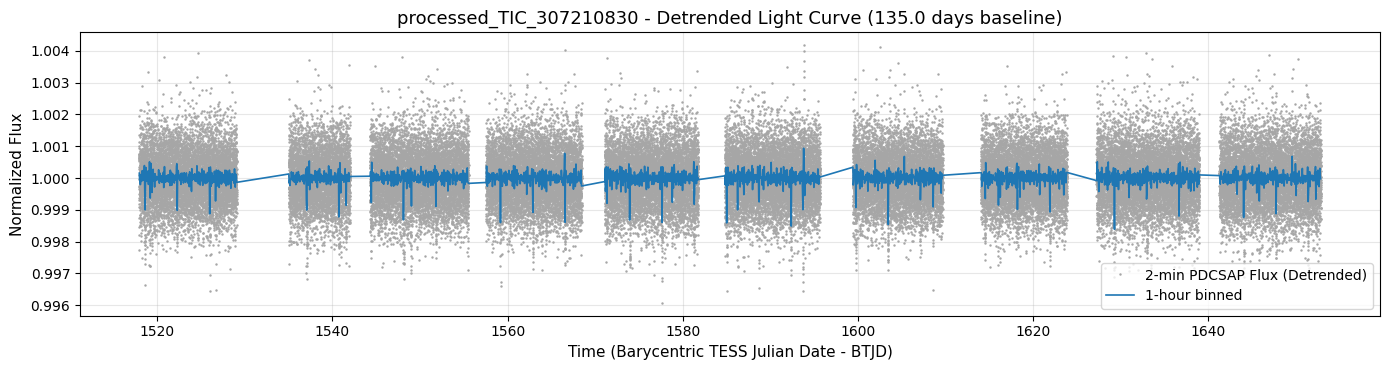

In [3]:
ensure_light_curve_loaded()

fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(time, flux, ".", color="0.65", ms=1.5, label="2-min PDCSAP Flux (Detrended)")
# Overlay a 1-hour binned curve for visual trend clarity
tb_1h, fb_1h, _ = bin_series(time, flux, flux_err if flux_err is not None else np.ones_like(flux), 60)
ax.plot(tb_1h, fb_1h, "-", color="tab:blue", lw=1.2, label="1-hour binned")
ax.set_xlabel("Time (Barycentric TESS Julian Date - BTJD)")
ax.set_ylabel("Normalized Flux")
ax.set_title(f"{star_name} - Detrended Light Curve ({baseline_d:.1f} days baseline)")
ax.legend(loc="lower right")
plt.show()

## Step 2: Light Curve Binning for Accelerated Transit Search
Searching 80,000+ trial periods over 75,000 points is computationally intensive.
By binning the 2-minute cadence data into 10-minute bins, we reduce the data size by ~5x without reducing the detectability of typical transit signals (which last 0.5 to 5 hours).

In [4]:
ensure_light_curve_loaded()

tb, fb, eb = bin_series(time, flux, flux_err if flux_err is not None else np.ones_like(flux), minutes=10)
print(f"Original points: {len(time):,} (2-minute cadence)")
print(f"Binned points:   {len(tb):,} (10-minute cadence)")
print(f"Speedup factor:  ~{len(time) / len(tb):.1f}x")

Original points: 75,041 (2-minute cadence)
Binned points:   15,132 (10-minute cadence)
Speedup factor:  ~5.0x


## Step 3: Generating the Optimal Log-Spaced Period Grid
In BLS, if the period grid step is too coarse, the cumulative phase error across the observational baseline $\Delta t$ will smear out the transit box.
To guarantee phase error is less than one-third of the shortest transit duration ($\tau_{\min} / 3$), the grid step in natural logarithm space must be:
$$d(\ln P) \le \frac{\tau_{\min}}{3 \times \Delta t}$$

In [5]:
ensure_light_curve_loaded()

durations_h = (0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0)
durations_d = np.array(durations_h) / 24.0

period_min = 0.5
period_max = min(baseline_d / 2.0, 40.0)

periods = make_period_grid(baseline_d, period_min, period_max, durations_d.min())
print(f"Period search range: {period_min} to {period_max:.1f} days")
print(f"Number of trial periods: {len(periods):,}")
print(f"Durations tested: {durations_h} hours")

Period search range: 0.5 to 40.0 days
Number of trial periods: 85,171
Durations tested: (0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0) hours


## Step 4: Running BLS Transit Search (Iteration 1)
We run the Box Least Squares periodogram on the binned data to locate the strongest periodic transit signal.

In [6]:
ensure_period_grid()

print(f"Running Box Least Squares on {len(tb):,} binned points across {len(periods):,} trial periods...")
print("  (This search takes ~40 seconds, finding the highest SNR peak...)")
res1 = bls_search(tb, fb, eb, periods, durations_d)

print(f"\nHighest Peak Detected:")
print(f"  Period:   {res1['period']:.4f} days")
print(f"  T0:       {res1['t0']:.4f} BTJD")
print(f"  Duration: {res1['duration'] * 24:.2f} hours")
print(f"  Depth:    {res1['depth'] * 1e6:.1f} ppm")
print(f"  SNR:      {res1['snr']:.2f}")
print(f"  SDE:      {res1['sde']:.2f}")

Running Box Least Squares on 15,132 binned points across 85,171 trial periods...
  (This search takes ~40 seconds, finding the highest SNR peak...)

Highest Peak Detected:
  Period:   3.6906 days
  T0:       1518.5919 BTJD
  Duration: 1.00 hours
  Depth:    1382.2 ppm
  SNR:      53.29
  SDE:      57.07


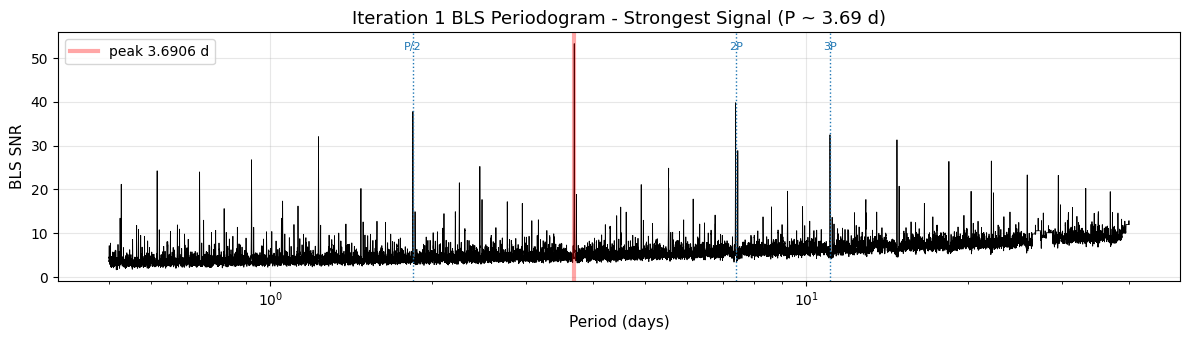

In [7]:
ensure_light_curve_loaded()
if "res1" not in globals() or res1 is None:
    raise RuntimeError("Missing 'res1': Please run Step 4 (Cell 10) first to execute the initial BLS search.")

det1 = {
    "planet": 1,
    **res1,
    "t": time.copy(),
    "f": flux.copy(),
    "e": flux_err.copy() if flux_err is not None else np.ones_like(flux),
}
fig, ax = plt.subplots(figsize=(12, 3.5))
plot_periodogram(det1, ax=ax, title="Iteration 1 BLS Periodogram - Strongest Signal (P ~ 3.69 d)")
plt.show()

## Step 5: Peak Refinement & Phase-Folded Transit Fit
We now refine the candidate transit parameters on the full-cadence data using a narrow period grid around the peak, and phase-fold the light curve to inspect the transit profile.

Refined Parameters:
  Period:   3.69078 days
  T0:       1518.58895 BTJD
  Duration: 1.11 hours
  Depth:    1366.8 ppm
  SNR:      55.47


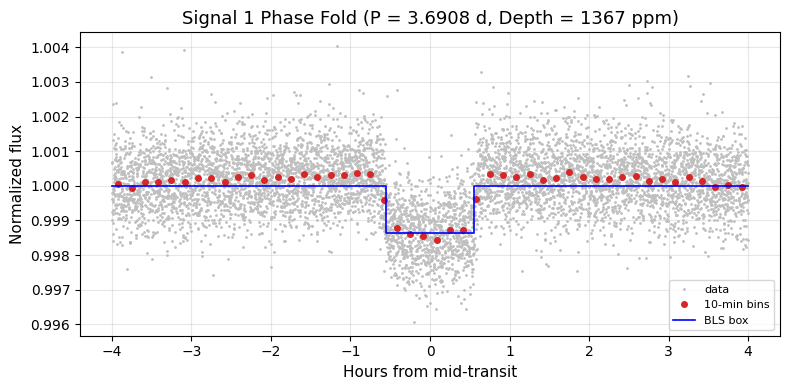

In [8]:
ensure_light_curve_loaded()
if "res1" not in globals() or res1 is None:
    raise RuntimeError("Missing 'res1': Please run Step 4 (Cell 10) first to detect the candidate signal.")

if "det1" not in globals() or det1 is None:
    det1 = {
        "planet": 1,
        **res1,
        "t": time.copy(),
        "f": flux.copy(),
        "e": flux_err.copy() if flux_err is not None else np.ones_like(flux),
    }

best1 = dict(res1)
refined1 = refine(time, flux, flux_err if flux_err is not None else np.ones_like(flux),
                  best1["period"], best1["t0"], best1["duration"])
best1.update(refined1)
det1.update(best1)

print(f"Refined Parameters:")
print(f"  Period:   {best1['period']:.5f} days")
print(f"  T0:       {best1['t0']:.5f} BTJD")
print(f"  Duration: {best1['duration'] * 24:.2f} hours")
print(f"  Depth:    {best1['depth'] * 1e6:.1f} ppm")
print(f"  SNR:      {best1['snr']:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
plot_fold(det1, ax=ax, title=f"Signal 1 Phase Fold (P = {best1['period']:.4f} d, Depth = {best1['depth']*1e6:.0f} ppm)")
plt.show()

## Step 6: Statistical Vetting & False-Positive Tests
To ensure the signal is a genuine exoplanet transit rather than an eclipsing binary, instrumental noise spike, or single-transit event, we apply automated vetting checks:
- **Number of transits**: Requires $\ge 2$ observed transits.
- **Odd/Even transit depth difference**: Eclipsing binaries have primary and secondary eclipses with alternating depths; true planets have identical depths ($\Delta \sigma < 3$).
- **Secondary eclipse**: Checks if there is a detectable dip at phase 0.5 ($\sigma_{\text{sec}} < 3$).
- **Red-Noise SNR**: Evaluates SNR using scatter measured across the transit-duration timescale.

In [9]:
ensure_light_curve_loaded()
if "best1" not in globals() or best1 is None:
    raise RuntimeError("Missing 'best1': Please run Step 5 (Cell 13) first to refine candidate parameters.")

v1 = vet(time, flux, flux_err if flux_err is not None else np.ones_like(flux),
         best1["period"], best1["t0"], best1["duration"])
snr_red1 = red_noise_snr(time, flux, best1["duration"], best1["depth"], v1["n_transits"])

print("--- Vetting Results for Signal 1 ---")
print(f"Number of transits:  {v1['n_transits']}")
print(f"Odd transit depth:   {v1['odd_depth']*1e6:.1f} ppm")
print(f"Even transit depth:  {v1['even_depth']*1e6:.1f} ppm")
print(f"Odd-even difference: {v1['odd_even_sigma']:.2f} sigma (Limit: < 3.0)")
print(f"Secondary eclipse:   {v1['secondary_sigma']:.2f} sigma (Limit: < 3.0)")
print(f"Red-noise SNR:       {snr_red1:.2f} (Threshold: >= 7.1)")
print(f"Vetting flags:       {v1['flags'] or 'None (Passed all checks!)'}")

--- Vetting Results for Signal 1 ---
Number of transits:  30
Odd transit depth:   1373.8 ppm
Even transit depth:  1361.2 ppm
Odd-even difference: 0.25 sigma (Limit: < 3.0)
Secondary eclipse:   0.57 sigma (Limit: < 3.0)
Red-noise SNR:       50.84 (Threshold: >= 7.1)
Vetting flags:       None (Passed all checks!)


## Step 7: Multi-Planet Discovery via Iterative Masking
Now we mask the transits of Signal 1 ($\pm 1.0 \times \text{duration}$) and repeat the BLS search to detect additional planets in the system!
Below we run the full end-to-end `detect()` function.

In [10]:
ensure_light_curve_loaded()

print("Running multi-planet iterative search (detecting up to 4 planets)...")
print("  (Each planet search takes ~40-50s; transits are masked sequentially...)\n")
table, details = detect.detect(time, flux, flux_err, max_planets=4, min_snr=7.1, verbose=True)

print("\n--- Multi-Planet Detection Summary Table ---")
cols = [c for c in SHOW_COLS if c in table.columns]
print(table[cols].round(3).to_string(index=False))

Running multi-planet iterative search (detecting up to 4 planets)...
  (Each planet search takes ~40-50s; transits are masked sequentially...)

75041 points over 135.0 d | searching 85171 periods (0.5-40.0 d) on 15132 points
  signal 1/4: running BLS on 15,132 points (85,171 periods)...
  signal 1: P = 3.6908 d, dur = 1.11 h, depth = 1367 ppm, SNR = 55.5 (red-noise 50.8), transits = 30, flags = none  [ACCEPTED, 40s]
  signal 2/4: running BLS on 14,733 points (85,171 periods)...
  signal 2: P = 7.4505 d, dur = 0.67 h, depth = 1333 ppm, SNR = 31.0 (red-noise 28.3), transits = 16, flags = none  [ACCEPTED, 41s]
  signal 3/4: running BLS on 14,604 points (85,171 periods)...
  signal 3: P = 2.2531 d, dur = 0.90 h, depth = 515 ppm, SNR = 23.5 (red-noise 22.3), transits = 46, flags = none  [ACCEPTED, 40s]
  signal 4/4: running BLS on 14,101 points (85,171 periods)...
  signal 4: P = 1.0491 d, dur = 1.24 h, depth = 177 ppm, SNR = 13.3 (red-noise 13.6), transits = 94, flags = ['secondary_eclipse

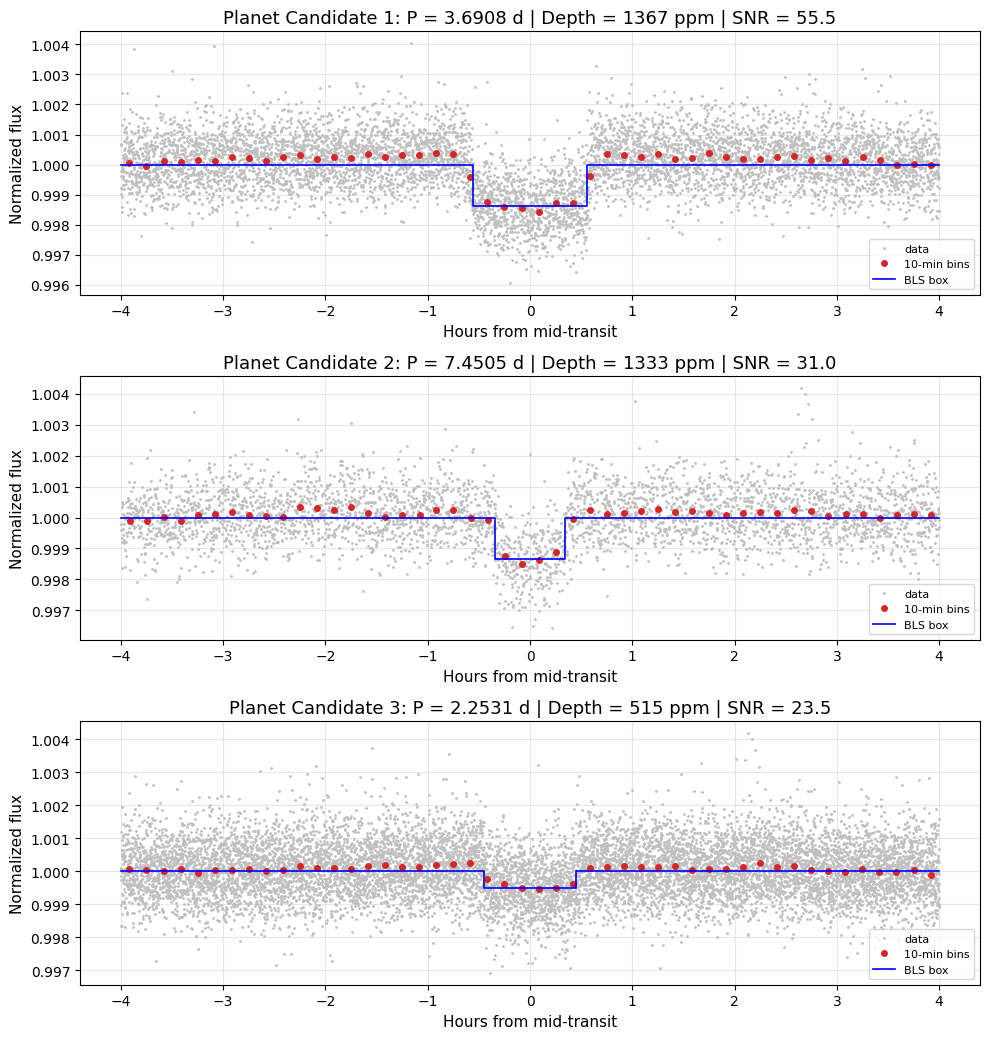

In [11]:
if "table" not in globals() or "details" not in globals() or table is None:
    raise RuntimeError("Missing 'table' or 'details': Please run Step 7 (Cell 17) first to detect planets.")

candidates = table[table.status == "candidate"]
if len(candidates) == 0:
    print("No signals met all vetting criteria as 'candidate'.")
else:
    fig, axes = plt.subplots(len(candidates), 1, figsize=(10, 3.5 * len(candidates)), squeeze=False)
    for idx, (_, row) in enumerate(candidates.iterrows()):
        p_num = int(row["planet"])
        det = details[p_num - 1]
        plot_fold(det, ax=axes[idx, 0],
                  title=f"Planet Candidate {p_num}: P = {row['period_d']:.4f} d | "
                        f"Depth = {row['depth_ppm']:.0f} ppm | SNR = {row['snr']:.1f}")
    plt.tight_layout()
    plt.show()

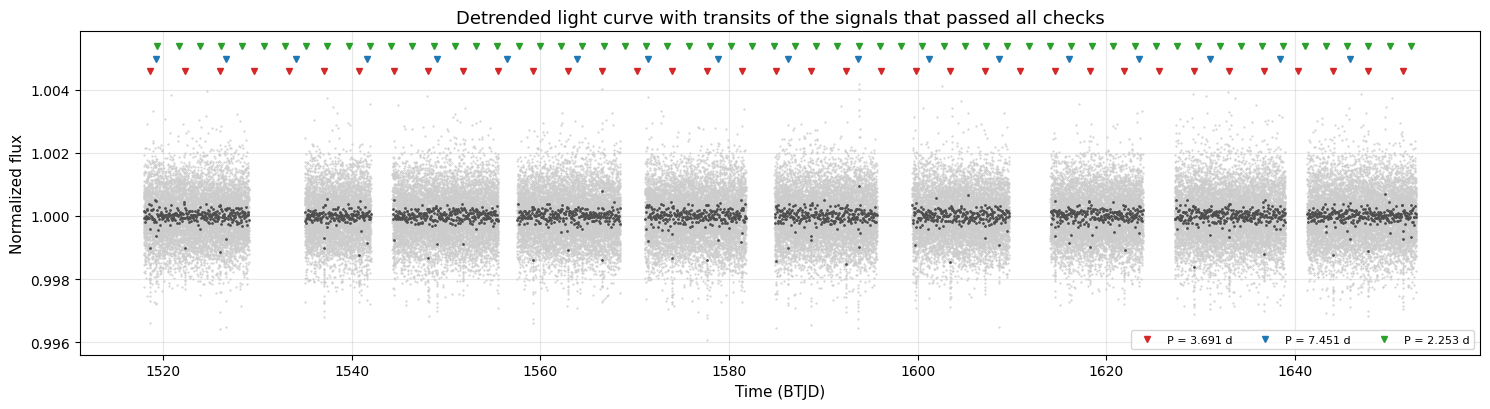

In [12]:
ensure_light_curve_loaded()
if "table" not in globals() or table is None:
    raise RuntimeError("Missing 'table': Please run Step 7 (Cell 17) first to detect signals.")

fig, ax = plt.subplots(figsize=(15, 4.2))
plot_overview(time, flux, table, ax=ax)
plt.show()

## Step 8: Validation on the Classification Dataset
We run `detect()` across the preprocessed stars in `data/processed/` (as generated by `preprocess.py` from `data/labels.csv`). By default, setting `PER_CLASS = None` processes the complete downloaded dataset (or set an integer like `8` to test a quick subset). For each star, we report how many periodic signals pass all vetting checks (`candidate`) and how many are significant but flagged (`flagged`).

For the `Transit` class, we query the NASA Exoplanet Archive to compare detected periods against known confirmed planet periods. A catalog period counts as **recovered** when a detected period matches it within 2 %. A match at half or twice the catalog period is reported separately as an alias.

To make batch analysis fast and transparent on the full dataset, execution is threaded (`WORKERS = 4`), displays progress updates, and automatically saves full tabular results to `results/detection/validation_results.csv`.

In [13]:
import re
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
import numpy as np
import pandas as pd

# ---- settings (the only things you may need to change) ----------------------------------------------------
NPZ_DIR = ROOT / "data" / "processed"       # directory of TIC_<id>.npz files
LABELS_CSV = ROOT / "data" / "labels.csv"   # labels table (from preprocessing/build_labels)
PER_CLASS = None                            # None = complete downloaded dataset; or an int (e.g. 8) to test a subset
INCLUDE_UNLABELED = False                   # True = also include any .npz files on disk not listed in labels.csv
TRANSIT_LABEL = "Transit"                   # class value that means "star hosts a transiting planet"
MAX_PLANETS = 3
PERIOD_TOL = 0.02                           # 2 % fractional tolerance when comparing with catalog periods
WORKERS = 4                                 # parallel threads (1 for sequential)
SAVE_RESULTS = True                         # save results table to results/detection/validation_results.csv

# Offline fallback. Replace/extend with your own mock if you have one: {tic_id: [known periods in days]}
MOCK_CATALOG = {307210830: [2.2531, 3.6907, 7.4507]}   # L 98-59 b, c, d


def tic_of(x):
    return int(re.search(r"\d+", str(x)).group())


def find_labels():
    """Return (tic -> class) from LABELS_CSV or the first valid labels CSV under data/."""
    tic_names = ["tic", "tic_id", "ticid", "star_id", "star", "id", "name"]
    cls_names = ["class", "label", "type", "kind", "category", "target"]
    paths = [Path(LABELS_CSV)] if LABELS_CSV and Path(LABELS_CSV).exists() else [ROOT / "data" / "labels.csv"] + sorted((ROOT / "data").rglob("*.csv"))
    for p in paths:
        if not p.exists() or "full" in p.parts or p.name == "failed.csv":
            continue
        try:
            df_l = pd.read_csv(p)
        except Exception:
            continue
        cols = {c.strip().lower(): c for c in df_l.columns}
        tc = next((cols[n] for n in tic_names if n in cols), None)
        cc = next((cols[n] for n in cls_names if n in cols), None)
        if tc and cc:
            print(f"Label table: {p.relative_to(ROOT)}  (TIC column '{tc}', class column '{cc}')")
            return {tic_of(a): str(b) for a, b in zip(df_l[tc], df_l[cc])}
    raise FileNotFoundError("No valid CSV with a TIC column and a class column found under data/.")


def fetch_catalog(tics):
    """Known periods per TIC from the NASA Exoplanet Archive; falls back to MOCK_CATALOG when offline."""
    if not tics:
        return {}, "no stars requested"
    try:
        try:
            from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive
        except ImportError:
            from astroquery.nasa_exoplanet_archive import NasaExoplanetArchive
            
        cat = {}
        tic_list = list(tics)
        chunk_size = 50
        for i in range(0, len(tic_list), chunk_size):
            chunk = tic_list[i : i + chunk_size]
            ids = ",".join(f"'TIC {t}'" for t in chunk)
            tab = NasaExoplanetArchive.query_criteria(
                table="pscomppars", select="tic_id,pl_name,pl_orbper", where=f"tic_id in ({ids})"
            )
            for r in tab:
                if not np.ma.is_masked(r["pl_orbper"]):
                    cat.setdefault(tic_of(r["tic_id"]), []).append(float(r["pl_orbper"]))
        return cat, "NASA Exoplanet Archive (live query)"
    except Exception as ex:
        print(f"Catalog query failed ({type(ex).__name__}); using MOCK catalog fallback.")
        return dict(MOCK_CATALOG), "MOCK catalog (offline fallback)"


def period_match(p_det, p_cat, tol=PERIOD_TOL):
    """'exact', 'half' (P_det ~ P/2), 'double' (P_det ~ 2P) or None."""
    for label, f in (("exact", 1.0), ("half", 0.5), ("double", 2.0)):
        if abs(p_det - f * p_cat) / (f * p_cat) < tol:
            return label
    return None


labels = find_labels()
by_class = {}

# 1. Collect all preprocessed stars belonging to known classes from labels.csv
for tic, cls in labels.items():
    if (NPZ_DIR / f"TIC_{tic}.npz").exists():
        by_class.setdefault(cls, []).append(tic)

# 2. Optionally include any extra .npz files found on disk in data/processed
if INCLUDE_UNLABELED:
    all_disk_tics = {tic_of(p.stem) for p in NPZ_DIR.glob("TIC_*.npz")}
    extra = sorted(all_disk_tics - set(labels.keys()))
    if extra:
        by_class.setdefault("Other/Unlabeled", []).extend(extra)

# Apply sample limit if PER_CLASS is set, or keep the complete downloaded dataset
sample = {
    cls: sorted(t)[:PER_CLASS] if PER_CLASS is not None else sorted(t)
    for cls, t in sorted(by_class.items())
}

total_stars = sum(len(t) for t in sample.values())
print(f"\nTargeting {total_stars} stars across {len(sample)} categories:")
for c, t in sample.items():
    print(f"  - {c}: {len(t)} stars")

transit_tics = sample.get(TRANSIT_LABEL, [])
catalog, catalog_source = fetch_catalog(transit_tics)
print(f"\nCatalog source for transit verification: {catalog_source}")
if transit_tics:
    print(f"Known periods cataloged for {len(catalog)} / {len(transit_tics)} {TRANSIT_LABEL} stars.")


# Worker function to process one star
def process_single_star(cls, tic):
    npz_file = NPZ_DIR / f"TIC_{tic}.npz"
    t_s, f_s, e_s, _ = load_input(npz=str(npz_file))
    tbl, _ = detect.detect(t_s, f_s, e_s, max_planets=MAX_PLANETS, min_snr=7.1, verbose=False)
    clean = tbl[tbl.status == "candidate"]          # significant and passed every vetting check
    flagged = tbl[tbl.status == "flagged"]          # significant but failed a vetting check
    found = list(clean.period_d) + list(flagged.period_d)
    
    row = {
        "class": cls,
        "tic": tic,
        "n_candidate": len(clean),
        "n_flagged": len(flagged),
        "periods_d": ", ".join(f"{p:.3f}" for p in clean.period_d),
    }
    if cls == TRANSIT_LABEL:
        known = catalog.get(tic, [])
        hits = [{m for p in found if (m := period_match(p, pc))} for pc in known]
        row.update(
            n_known=len(known),
            recovered=sum("exact" in h for h in hits),
            alias_only=sum(bool(h) and "exact" not in h for h in hits),
            known_periods_d=", ".join(f"{p:.3f}" for p in known),
        )
    return row


rows = []
tasks = [(cls, tic) for cls, tics in sample.items() for tic in tics]
print(f"\nRunning detection on {len(tasks)} stars (workers={WORKERS})...")

t_start = time.time()
if WORKERS > 1:
    with ThreadPoolExecutor(max_workers=WORKERS) as pool:
        futures = {pool.submit(process_single_star, cls, tic): (cls, tic) for cls, tic in tasks}
        count = 0
        for fut in as_completed(futures):
            count += 1
            row = fut.result()
            rows.append(row)
            if count % 10 == 0 or count == len(tasks):
                print(f"  Processed {count}/{len(tasks)} stars ({count/len(tasks)*100:.1f}%)...", flush=True)
else:
    for idx, (cls, tic) in enumerate(tasks, 1):
        row = process_single_star(cls, tic)
        rows.append(row)
        if idx % 10 == 0 or idx == len(tasks):
            print(f"  Processed {idx}/{len(tasks)} stars ({idx/len(tasks)*100:.1f}%)...", flush=True)

elapsed = time.time() - t_start
print(f"\nDetection complete in {elapsed:.1f} s ({elapsed/max(1, len(tasks)):.2f} s/star).")

# Sort rows to maintain deterministic order (class, then tic)
results = pd.DataFrame(rows).sort_values(["class", "tic"]).reset_index(drop=True)
display(results)

if SAVE_RESULTS:
    out_dir = ROOT / "results" / "detection"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_file = out_dir / "validation_results.csv"
    results.to_csv(out_file, index=False)
    print(f"\nSaved full results to {out_file.relative_to(ROOT)}")

summary = results.groupby("class").agg(
    stars=("tic", "count"),
    with_clean_candidate=("n_candidate", lambda s: int((s > 0).sum())),
    clean_candidates=("n_candidate", "sum"),
    flagged_signals=("n_flagged", "sum"),
)
print("\nPer-class summary:")
display(summary)

tr = results[results["class"] == TRANSIT_LABEL]
if len(tr) and "n_known" in tr.columns and tr.n_known.sum() > 0:
    print(f"\nTransit stars vs {catalog_source}: recovered {int(tr.recovered.sum())} of {int(tr.n_known.sum())} "
          f"catalog periods within {PERIOD_TOL:.0%} ({int(tr.alias_only.sum())} more matched only as a P/2 or 2P alias).")
elif len(tr):
    print("\nNo catalog periods found for the sampled Transit stars; nothing to compare.")


Label table: data\labels.csv  (TIC column 'tic_id', class column 'label')

Targeting 158 stars across 3 categories:
  - Eclipsing Binary: 78 stars
  - Other: 24 stars
  - Transit: 56 stars
Catalog query failed (TypeError); using MOCK catalog fallback.

Catalog source for transit verification: MOCK catalog (offline fallback)
Known periods cataloged for 1 / 56 Transit stars.

Running detection on 158 stars (workers=4)...
  Processed 10/158 stars (6.3%)...
  Processed 20/158 stars (12.7%)...
  Processed 30/158 stars (19.0%)...
  Processed 40/158 stars (25.3%)...
  Processed 50/158 stars (31.6%)...
  Processed 60/158 stars (38.0%)...
  Processed 70/158 stars (44.3%)...
  Processed 80/158 stars (50.6%)...
  Processed 90/158 stars (57.0%)...
  Processed 100/158 stars (63.3%)...
  Processed 110/158 stars (69.6%)...
  Processed 120/158 stars (75.9%)...
  Processed 130/158 stars (82.3%)...
  Processed 140/158 stars (88.6%)...
  Processed 150/158 stars (94.9%)...
  Processed 158/158 stars (100.0

,class,tic,n_candidate,n_flagged,periods_d,n_known,recovered,alias_only,known_periods_d
0,Eclipsing Binary,1129452,0,0,,NaN,NaN,NaN,NaN
1,Eclipsing Binary,5981829,0,3,,NaN,NaN,NaN,NaN
2,Eclipsing Binary,11748495,0,1,,NaN,NaN,NaN,NaN
3,Eclipsing Binary,12723924,0,2,,NaN,NaN,NaN,NaN
4,Eclipsing Binary,35655828,1,2,1.221,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
153,Transit,406976746,0,0,,0.0,0.0,0.0,
154,Transit,445805961,0,1,,0.0,0.0,0.0,
155,Transit,452808876,0,1,,0.0,0.0,0.0,
156,Transit,452866790,1,0,1.198,0.0,0.0,0.0,



Saved full results to results\detection\validation_results.csv

Per-class summary:


,stars,with_clean_candidate,clean_candidates,flagged_signals
class,,,,
Eclipsing Binary,78,24,25,133
Other,24,10,11,8
Transit,56,22,25,16



No catalog periods found for the sampled Transit stars; nothing to compare.


## Summary & Key Takeaways
1. **BLS Search & Period Grid**: Using a log-spaced grid guarantees sensitivity across all periods up to $P_{\max}$.
2. **Speed & Precision**: 10-minute binning speeds up the search 5x, followed by full-cadence narrow refinement for precision.
3. **Iterative Multi-Planet Recovery**: Masking each detected planet enables clean detection of secondary, tertiary, and smaller signals (detected signals match the known periods of L 98-59 c, d, and b).
4. **Vetting Robustness**: Combined odd/even depth tests, secondary eclipse tests, and red-noise SNR eliminate false positives from eclipsing binaries and correlated systematics.